<a href="https://colab.research.google.com/github/Shubh170206/Major-project/blob/main/train_leaf_disease_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, glob

# Set Kaggle API credentials directly
os.environ["KAGGLE_USERNAME"] = "your_kaggle_username"  # Replace with your Kaggle username
os.environ["KAGGLE_KEY"] = "KGAT_8cbc8c19c29cd88fd3b5ac2477d1eb2a"

# Download and extract the dataset
os.system("kaggle datasets download -d abdallahalidev/plantvillage-dataset")
os.system("unzip -q -o plantvillage-dataset.zip")

# Auto-find the 'color' folder
matches = glob.glob("**/color", recursive=True)
DATA_DIR = matches[0]
print("Using:", DATA_DIR)


Using: plantvillage dataset/color


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)

class_names = train_ds.class_names
print(len(class_names), "classes")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
38 classes


In [ ]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=IMG_SIZE + (3,)),
    augment,
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(class_names), activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("leaf_model.keras", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=8, callbacks=callbacks)

Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 104s 71ms/step - accuracy: 0.8580 - loss: 0.5154 - val_accuracy: 0.9267 - val_loss: 0.2485
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 99s 73ms/step - accuracy: 0.9245 - loss: 0.2406 - val_accuracy: 0.9430 - val_loss: 0.1880
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 97s 71ms/step - accuracy: 0.9339 - loss: 0.2027 - val_accuracy: 0.9404 - val_loss: 0.1834
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 96s 71ms/step - accuracy: 0.9395 - loss: 0.1844 - val_accuracy: 0.9380 - val_loss: 0.1844
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 97s 71ms/step - accuracy: 0.9411 - loss: 0.1771 - val_accuracy: 0.9490 - val_loss: 0.1598
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 99s 73ms/step - accuracy: 0.9424 - loss: 0.1707 - val_accuracy: 0.9441 - val_loss: 0.1713
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 97s 71ms/step - accuracy: 0.9460 - loss: 0.1652 - val_accuracy: 0.9503 - val_loss: 0.1516
Epoch 8/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 96s 71ms/step - accuracy: 0.9472 - loss: 

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.90      0.95      0.92       126
                                 Apple___Black_rot       0.97      1.00      0.99       132
                          Apple___Cedar_apple_rust       1.00      0.95      0.97        55
                                   Apple___healthy       0.99      0.97      0.98       329
                               Blueberry___healthy       1.00      0.98      0.99       295
          Cherry_(including_sour)___Powdery_mildew       1.00      0.98      0.99       232
                 Cherry_(including_sour)___healthy       0.98      0.98      0.98       167
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.76      0.95      0.85       108
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       219
               Corn_(maize)___Northern_Leaf_Blight       0.96      0.84      0.

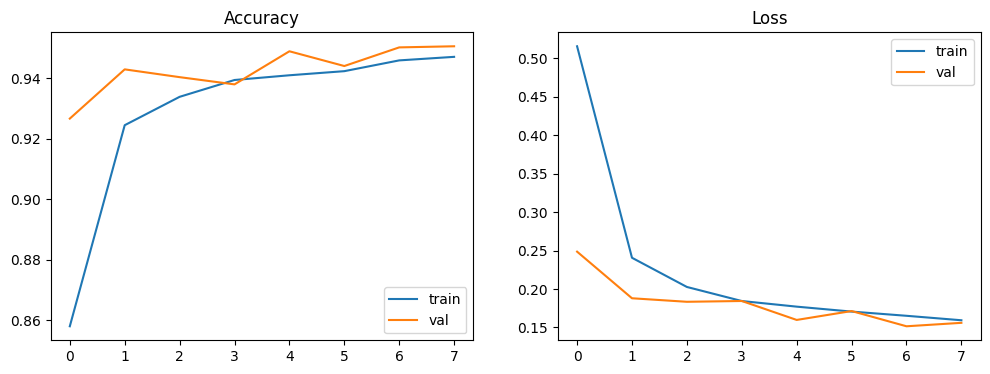

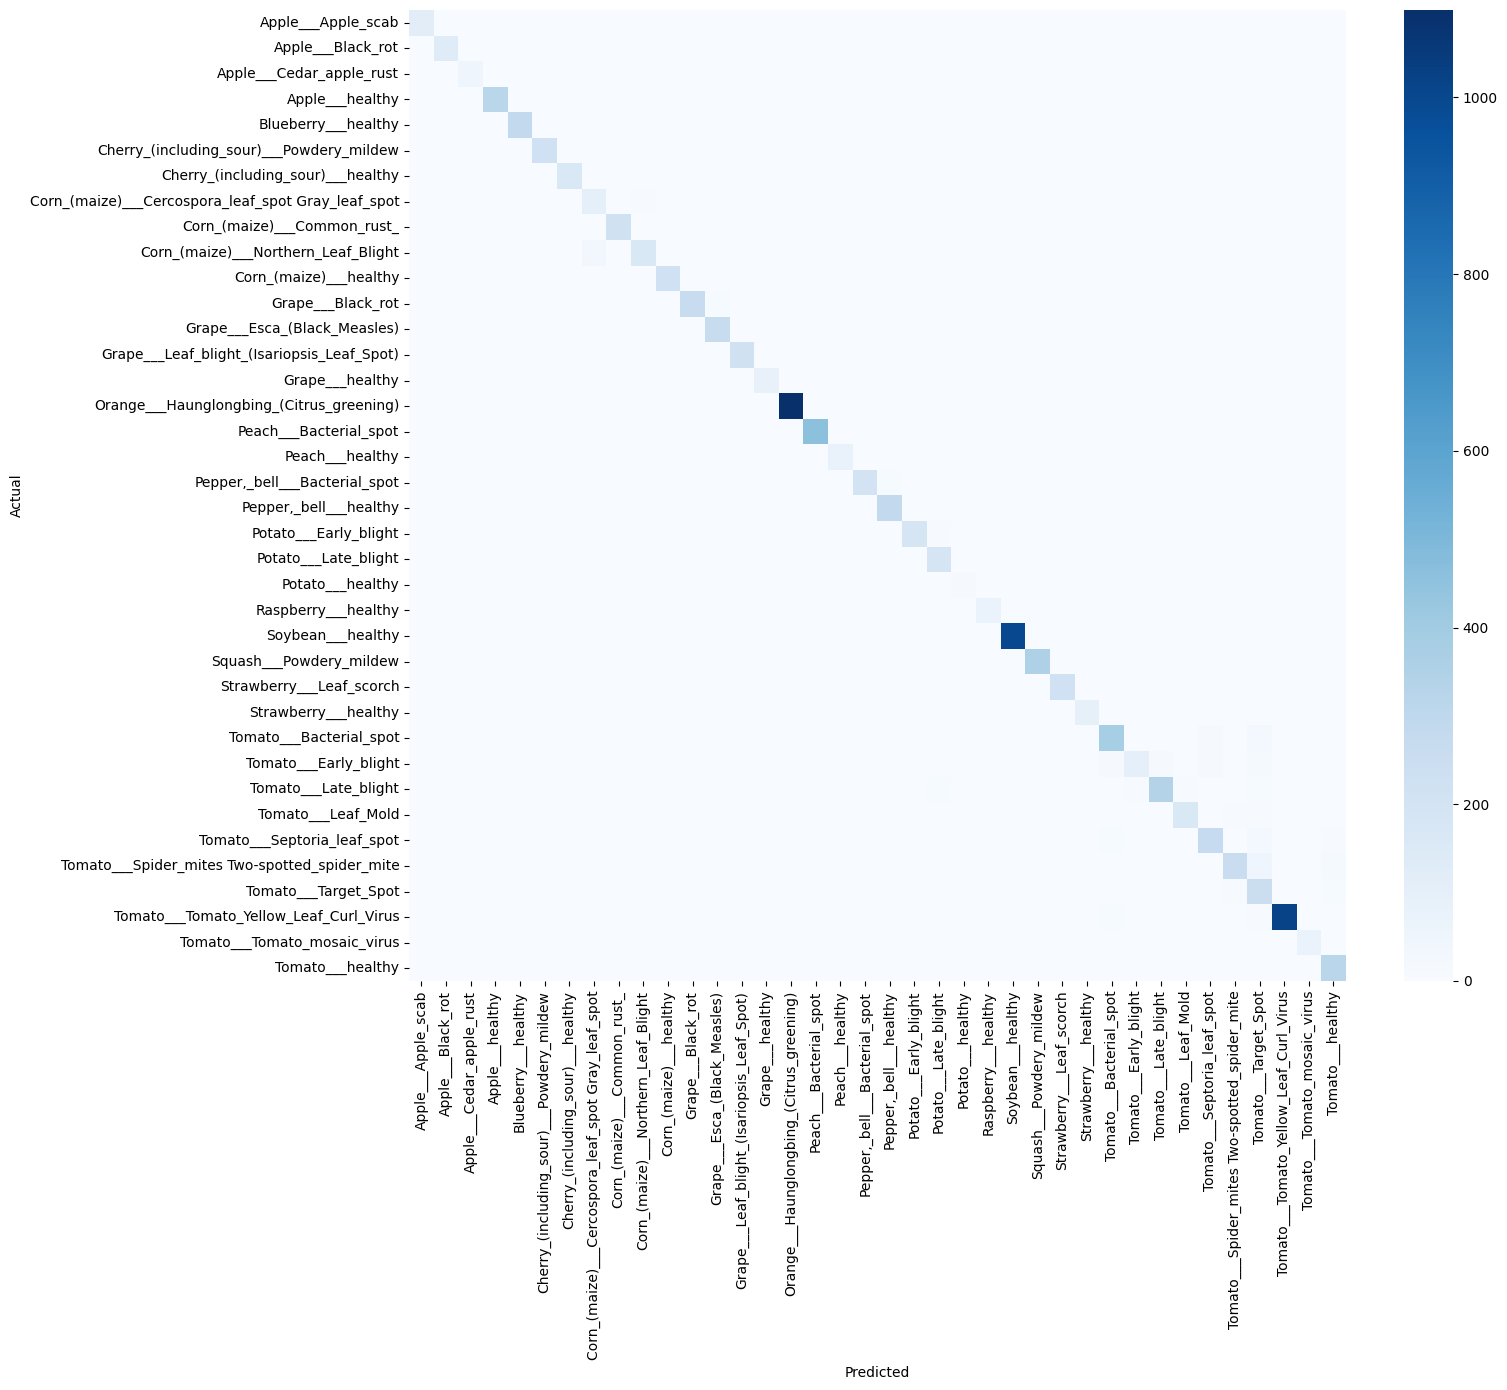

In [ ]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Accuracy / loss graph
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.savefig("training_curves.png", dpi=200)

# Predictions
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)

In [ ]:
import json
json.dump(class_names, open("class_names.json", "w"))

for f in ["leaf_model.keras", "class_names.json",
          "training_curves.png", "confusion_matrix.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>